In [3]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(
    "/content/ted_talks_cleaned.csv"
)

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (4005, 24)


,talk_id,title,speaker,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,tags,related_talks,url,description,transcript,title_clean,description_clean,transcript_clean,tags_clean,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,...,[],"{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",averting the climate crisis,with the same humor and humanity he exuded in ...,thank you so much chris and it's truly a great...,NaN,averting the climate crisis with the same humo...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,...,[],"{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...",the best stats you've ever seen,you've never seen data presented like this wit...,about 10 years ago i took on the task to teach...,NaN,the best stats you've ever seen you've never s...
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,...,[],"{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...",simplicity sells,new york times columnist david pogue takes aim...,music the sound of silence simon garfunkel hel...,NaN,simplicity sells new york times columnist davi...
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,...,[],{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,greening the ghetto,in an emotionally charged talk macarthur-winni...,if you're here today and i'm very happy that y...,NaN,greening the ghetto in an emotionally charged ...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,...,[],"{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,do schools kill creativity,sir ken robinson makes an entertaining and pro...,good morning how are you audience good it's be...,NaN,do schools kill creativity sir ken robinson ma...


In [5]:
print("Available columns:")

print(df.columns.tolist())

Available columns:
['talk_id', 'title', 'speaker', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'tags', 'related_talks', 'url', 'description', 'transcript', 'title_clean', 'description_clean', 'transcript_clean', 'tags_clean', 'combined_text']


In [6]:
required_columns = [
    "talk_id",
    "title",
    "combined_text"
]

for column in required_columns:

    if column not in df.columns:

        raise ValueError(
            f"Required column missing: {column}"
        )

print("All required columns are available!")

All required columns are available!


In [7]:
df["combined_text"] = (
    df["combined_text"]
    .fillna("")
    .astype(str)
)

df["title"] = (
    df["title"]
    .fillna("")
    .astype(str)
)

df = df[
    (df["combined_text"].str.strip() != "") &
    (df["title"].str.strip() != "")
].copy()

df = df.reset_index(drop=True)

print("Usable records:", len(df))

Usable records: 4005


In [8]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [9]:
tfidf_matrix = tfidf_vectorizer.fit_transform(
    df["combined_text"]
)

print("TF-IDF vectorization completed!")

TF-IDF vectorization completed!


In [10]:
print("TF-IDF Matrix Shape:")

print(tfidf_matrix.shape)

TF-IDF Matrix Shape:
(4005, 10000)


In [11]:
feature_names = tfidf_vectorizer.get_feature_names_out()

print("Total vocabulary size:", len(feature_names))

print("\nFirst 50 vocabulary terms:")

print(feature_names[:50])

Total vocabulary size: 10000

First 50 vocabulary terms:
['000' '000 000' '000 children' '000 dollars' '000 feet' '000 miles'
 '000 people' '000 times' '000 year' '000 years' '10' '10 000' '10 15'
 '10 20' '10 billion' '10 million' '10 minutes' '10 percent' '10 times'
 '10 year' '10 years' '100' '100 000' '100 billion' '100 million'
 '100 percent' '100 times' '100 years' '11' '11 years' '11th' '12'
 '12 000' '12 years' '120' '125' '13' '13 years' '130' '14' '14 year'
 '14 years' '140' '15' '15 000' '15 minutes' '15 percent' '15 year'
 '15 years' '150']


In [12]:
tfidf_sample = pd.DataFrame(
    tfidf_matrix[:5].toarray(),
    columns=feature_names
)

tfidf_sample.iloc[:, :20]

,000,000 000,000 children,000 dollars,000 feet,000 miles,000 people,000 times,000 year,000 years,10,10 000,10 15,10 20,10 billion,10 million,10 minutes,10 percent,10 times,10 year
0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.008203,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.024082,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.008709,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.008523,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.033790,0.0,0.0,0.0,0.0,0.0,0.015781,0.0,0.0,0.0,0.016533,0.031561,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
similarity_matrix = cosine_similarity(
    tfidf_matrix
)

print("Similarity matrix shape:")

print(similarity_matrix.shape)

Similarity matrix shape:
(4005, 4005)


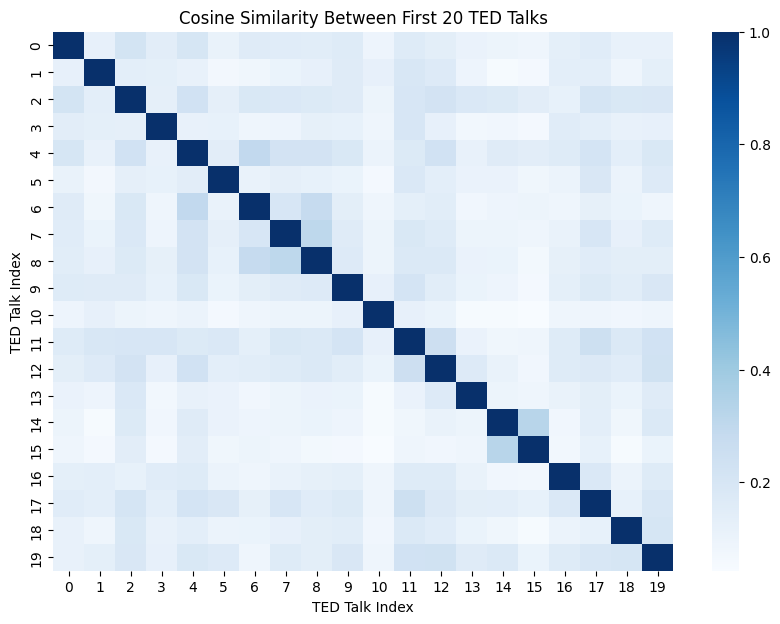

In [14]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    similarity_matrix[:20, :20],
    cmap="Blues"
)

plt.title("Cosine Similarity Between First 20 TED Talks")

plt.xlabel("TED Talk Index")

plt.ylabel("TED Talk Index")

plt.show()

In [15]:
def recommend_talks(talk_index, top_n=5):

    similarity_scores = cosine_similarity(
        tfidf_matrix[talk_index],
        tfidf_matrix
    ).flatten()

    # Exclude the selected talk itself

    similarity_scores[talk_index] = -1

    # Get the indices of the highest similarity scores

    recommended_indices = np.argsort(
        similarity_scores
    )[::-1][:top_n]

    recommendations = df.iloc[
        recommended_indices
    ][["talk_id", "title"]].copy()

    recommendations["similarity_score"] = (
        similarity_scores[recommended_indices]
    )

    return recommendations.reset_index(drop=True)

In [16]:
selected_indices = [
    0,
    len(df) // 3,
    (2 * len(df)) // 3
]

for talk_index in selected_indices:

    selected_talk = df.iloc[talk_index]["title"]

    print("\nSelected TED Talk:")

    print(selected_talk)

    print("\nRecommended TED Talks:")

    recommendations = recommend_talks(
        talk_index,
        top_n=5
    )

    print(recommendations)

    print("-" * 70)


Selected TED Talk:
Averting the climate crisis

Recommended TED Talks:
   talk_id                                            title  similarity_score
0      243               New thinking on the climate crisis          0.353645
1    54715              How we can turn the tide on climate          0.316076
2     2441          The case for optimism on climate change          0.297032
3    60080  How we could change the planet's climate future          0.295315
4     2784       A climate solution where all sides can win          0.294376
----------------------------------------------------------------------

Selected TED Talk:
Before I die I want to ...

Recommended TED Talks:
   talk_id                                              title  \
0     1966                 How public spaces make cities work   
1     2212  There’s a better way to die, and architecture ...   
2     9219   Talk about your death while you're still healthy   
3     1399                             Let's talk about dy

In [17]:
def search_talk(title):

    matches = df[
        df["title"].str.contains(
            title,
            case=False,
            na=False,
            regex=False
        )
    ]

    return matches[["talk_id", "title"]].head(10)

In [18]:
search_talk("artificial intelligence")

,talk_id,title


In [19]:
df[
    df["title"].str.contains(
        "artificial intelligence",
        case=False,
        na=False,
        regex=False
    )
][["title"]].head(10)

,title


In [20]:
recommend_talks(120, top_n=5)

,talk_id,title,similarity_score
0,2000,The Museum of Four in the Morning,0.343306
1,2027,Two nerdy obsessions meet -- and it's magic,0.280565
2,87,Nerdcore comedy,0.213984
3,2242,"The dancer, the singer, the cellist ... and a ...",0.202862
4,2795,Songs that bring history to life,0.180490


In [21]:
import joblib
from pathlib import Path

model_path = Path("../models")

model_path.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    tfidf_vectorizer,
    model_path / "ted_tfidf_vectorizer.pkl"
)

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!
